# GAN-based Synthetic MEL Generation — Correction Response

**Purpose:** the paper's second round of corrections asked for generative-AI (GAN/diffusion)
synthetic minority-class data. This notebook trains a lightweight DCGAN on the 35 real MEL
training images and evaluates the synthetic output *before* it ever touches the classifier.

**Important caveat, stated up front (and repeated in the paper):** 35 images is far below
where GAN training is normally considered reliable. This notebook is designed to produce an
honest answer either way — including a negative result — not to force a good-looking number.

**What this notebook does, in order:**
1. Load only the 35 real MEL training images (via the existing `expA_train.csv` split).
2. Train a small DCGAN generator/discriminator at 64x64 resolution using DiffAugment
   (differentiable augmentation), the standard stabilization trick for small-data GAN training.
3. Generate a batch of synthetic MEL images and save them + a manifest CSV.
4. Evaluate synthetic quality quantitatively using the *existing SSL encoder*
   (`ssl_encoder_real_24000.pth`) as a domain-specific feature extractor:
   mean feature-space cosine similarity to real MEL images, and a Frechet-distance-style
   score in that embedding space (this doubles as the "feature similarity" evaluation the
   correction document explicitly asked for).
5. Save a visual grid of samples for manual inspection.

This notebook does **not** modify the classifier. Whether to actually use this synthetic data
for fine-tuning is decided in `ssl-finetune-synthetic-augmented.ipynb`, after reviewing the
metrics and grid produced here.


In [14]:
import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils as vutils
from PIL import Image
import matplotlib.pyplot as plt

import sys
import os

# Path to the dataset folder containing config.py
dataset_dir = '/kaggle/input/skin-ssl-code/skin-ssl-code'

if os.path.exists(dataset_dir):
    sys.path.append(dataset_dir)
else:
    # Fallback search inside /kaggle/input in case of single nested directory structure
    for root, dirs, files in os.walk('/kaggle/input'):
        if 'config.py' in files:
            sys.path.append(root)
            break

import config

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

BACKUP_DIR = config.CSV_DIR
LABELED_DIR = config.LABELED_DIR
OUTPUT_DIR = config.OUTPUT_ROOT

SYNTH_DIR = os.path.join(OUTPUT_DIR, 'synthetic_mel')
os.makedirs(SYNTH_DIR, exist_ok=True)

IMG_SIZE = 64          # small on purpose: cheaper + more stable for a 35-image GAN
LATENT_DIM = 100
BATCH_SIZE = 8         # small dataset, small batch
N_ITERS = 3000         # DiffAugment GANs on tiny data typically need a few thousand steps,
                        # not epochs in the usual sense; ~3000 iters at batch 8 is a few
                        # minutes on a T4 with a model this small


Device: cuda


In [15]:
# =====================================================================
# LOAD THE 35 REAL MEL TRAINING IMAGES ONLY
# =====================================================================
import os
import pandas as pd
from PIL import Image

# Locate expA_train.csv dynamically in /kaggle/input
csv_name = 'expA_train.csv'
csv_path = None

for root, dirs, files in os.walk('/kaggle/input'):
    if csv_name in files:
        csv_path = os.path.join(root, csv_name)
        break

if csv_path is None:
    raise FileNotFoundError(f"Could not find {csv_name} anywhere inside /kaggle/input")

print(f"Found CSV at: {csv_path}")
train_df = pd.read_csv(csv_path)

mel_df = train_df[train_df['label'] == 'MEL'].reset_index(drop=True)
print(f"Real MEL training images available: {len(mel_df)}")
assert len(mel_df) > 0, "No MEL images found in expA_train.csv"

# Make sure LABELED_DIR also resolves dynamically if relative
if not os.path.isabs(LABELED_DIR):
    # Locate the image folder inside /kaggle/input
    for root, dirs, files in os.walk('/kaggle/input'):
        if any(f.endswith('.jpg') for f in files):
            LABELED_DIR = root
            break

print(f"Using image directory: {LABELED_DIR}")

gan_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

class MELOnlyDataset(Dataset):
    def __init__(self, df, image_dir, transform):
        self.df = df
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.image_dir, f"{row['image']}.jpg")
        img = Image.open(img_path).convert('RGB')
        return self.transform(img)

mel_dataset = MELOnlyDataset(mel_df, LABELED_DIR, gan_transform)
mel_loader = DataLoader(mel_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
print(f"Batches per pass over real MEL data: {len(mel_loader)}")


Found CSV at: /kaggle/input/datasets/ittisamurtunib/dataset/CSVs-20260711T054424Z-2-001/CSVs/expA_train.csv
Real MEL training images available: 35
Using image directory: /kaggle/input/datasets/ittisamurtunib/dataset/ISIC_2019_Training_Input/ISIC_2019_Training_Input
Batches per pass over real MEL data: 5


In [16]:
# =====================================================================
# DIFFAUGMENT -- differentiable augmentation for small-data GAN stability
# (Zhao et al. 2020, "Differentiable Augmentation for Data-Efficient GAN
# Training"). Applied identically to real and fake batches before they
# reach the discriminator, so the discriminator cannot use augmentation
# artifacts as a shortcut. This is the standard trick that makes GAN
# training even attemptable with datasets in the dozens-to-hundreds range.
# =====================================================================

def diffaugment_translation(x, ratio=0.125):
    shift = int(x.size(2) * ratio + 0.5)
    tx = torch.randint(-shift, shift + 1, (x.size(0),), device=x.device)
    ty = torch.randint(-shift, shift + 1, (x.size(0),), device=x.device)
    pad = (shift, shift, shift, shift)
    x_pad = F.pad(x, pad, mode='reflect')
    out = torch.zeros_like(x)
    for i in range(x.size(0)):
        out[i] = x_pad[i, :, shift + tx[i]: shift + tx[i] + x.size(2),
                              shift + ty[i]: shift + ty[i] + x.size(3)]
    return out

def diffaugment_cutout(x, ratio=0.5):
    cutout_size = int(x.size(2) * ratio + 0.5), int(x.size(3) * ratio + 0.5)
    offset_x = torch.randint(0, x.size(2) + (1 - cutout_size[0] % 2), (x.size(0),), device=x.device)
    offset_y = torch.randint(0, x.size(3) + (1 - cutout_size[1] % 2), (x.size(0),), device=x.device)
    mask = torch.ones_like(x)
    for i in range(x.size(0)):
        x0 = max(offset_x[i] - cutout_size[0] // 2, 0)
        x1 = min(offset_x[i] + cutout_size[0] // 2, x.size(2))
        y0 = max(offset_y[i] - cutout_size[1] // 2, 0)
        y1 = min(offset_y[i] + cutout_size[1] // 2, x.size(3))
        mask[i, :, x0:x1, y0:y1] = 0
    return x * mask

def diffaugment_color(x):
    x = x + (torch.rand(x.size(0), 1, 1, 1, device=x.device) - 0.5)
    x_mean = x.mean(dim=1, keepdim=True)
    x = (x - x_mean) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) * 2) + x_mean
    return x

def diffaugment(x):
    x = diffaugment_color(x)
    x = diffaugment_translation(x)
    x = diffaugment_cutout(x)
    return x


In [17]:
# =====================================================================
# LIGHTWEIGHT DCGAN -- kept small deliberately: with 35 training images
# a large generator has far more capacity to memorize than to generalize.
# =====================================================================

class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, feature_maps=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, feature_maps * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(feature_maps * 8), nn.ReLU(True),
            # 4x4
            nn.ConvTranspose2d(feature_maps * 8, feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 4), nn.ReLU(True),
            # 8x8
            nn.ConvTranspose2d(feature_maps * 4, feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 2), nn.ReLU(True),
            # 16x16
            nn.ConvTranspose2d(feature_maps * 2, feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps), nn.ReLU(True),
            # 32x32
            nn.ConvTranspose2d(feature_maps, 3, 4, 2, 1, bias=False),
            nn.Tanh()
            # 64x64
        )
    def forward(self, z):
        return self.net(z.view(z.size(0), -1, 1, 1))

class Discriminator(nn.Module):
    def __init__(self, feature_maps=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, feature_maps, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # 32x32
            nn.Conv2d(feature_maps, feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 2), nn.LeakyReLU(0.2, inplace=True),
            # 16x16
            nn.Conv2d(feature_maps * 2, feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 4), nn.LeakyReLU(0.2, inplace=True),
            # 8x8
            nn.Conv2d(feature_maps * 4, feature_maps * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 8), nn.LeakyReLU(0.2, inplace=True),
            # 4x4
            nn.Conv2d(feature_maps * 8, 1, 4, 1, 0, bias=False)
        )
    def forward(self, x):
        return self.net(x).view(-1)

def weights_init(m):
    classname = m.__class__.__name__
    if 'Conv' in classname:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif 'BatchNorm' in classname:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

netG = Generator().to(device)
netD = Discriminator().to(device)
netG.apply(weights_init)
netD.apply(weights_init)

optG = torch.optim.Adam(netG.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(netD.parameters(), lr=2e-4, betas=(0.5, 0.999))
criterion = nn.BCEWithLogitsLoss()


In [18]:
# =====================================================================
# TRAINING LOOP
# Non-saturating GAN loss, DiffAugment applied to both real and fake
# batches. Because the "epoch" over 35 images is meaningless, we train
# for a fixed number of iterations and cycle through the loader.
# =====================================================================

def infinite_loader(loader):
    while True:
        for batch in loader:
            yield batch

data_iter = infinite_loader(mel_loader)
g_losses, d_losses = [], []

for it in range(1, N_ITERS + 1):
    real = next(data_iter).to(device)
    b = real.size(0)

    # --- Discriminator step ---
    z = torch.randn(b, LATENT_DIM, device=device)
    fake = netG(z)

    real_aug = diffaugment(real)
    fake_aug = diffaugment(fake.detach())

    d_real = netD(real_aug)
    d_fake = netD(fake_aug)
    loss_d = criterion(d_real, torch.ones_like(d_real) * 0.9) + \
             criterion(d_fake, torch.zeros_like(d_fake))
    optD.zero_grad(); loss_d.backward(); optD.step()

    # --- Generator step ---
    z = torch.randn(b, LATENT_DIM, device=device)
    fake = netG(z)
    fake_aug = diffaugment(fake)
    d_fake_for_g = netD(fake_aug)
    loss_g = criterion(d_fake_for_g, torch.ones_like(d_fake_for_g))
    optG.zero_grad(); loss_g.backward(); optG.step()

    g_losses.append(loss_g.item())
    d_losses.append(loss_d.item())

    if it % 250 == 0:
        print(f"Iter {it}/{N_ITERS}  loss_D={loss_d.item():.3f}  loss_G={loss_g.item():.3f}")

torch.save(netG.state_dict(), os.path.join(OUTPUT_DIR, 'gan_mel_generator.pth'))
print("Generator checkpoint saved.")


Iter 250/3000  loss_D=0.688  loss_G=1.577
Iter 500/3000  loss_D=0.774  loss_G=2.161
Iter 750/3000  loss_D=1.182  loss_G=1.619
Iter 1000/3000  loss_D=1.173  loss_G=0.613
Iter 1250/3000  loss_D=1.149  loss_G=1.275
Iter 1500/3000  loss_D=1.283  loss_G=2.041
Iter 1750/3000  loss_D=0.515  loss_G=2.876
Iter 2000/3000  loss_D=1.334  loss_G=1.613
Iter 2250/3000  loss_D=1.488  loss_G=1.753
Iter 2500/3000  loss_D=1.444  loss_G=1.025
Iter 2750/3000  loss_D=1.491  loss_G=1.956
Iter 3000/3000  loss_D=1.146  loss_G=1.898
Generator checkpoint saved.


Saved 200 synthetic MEL images to outputs/synthetic_mel
Manifest written to outputs/synthetic_mel_manifest.csv


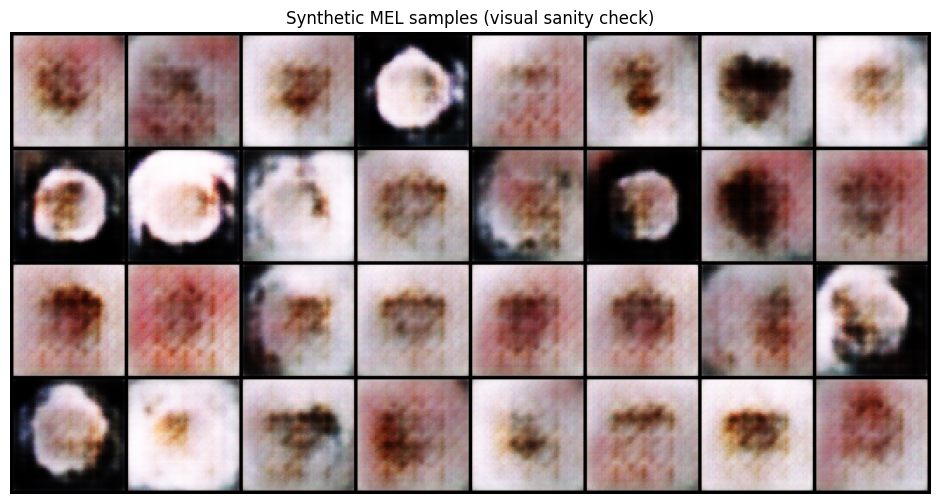

If these look like near-duplicates of a handful of real images, that IS mode collapse
-- report it as such. It is a legitimate, citable outcome for n=35 training images.


In [20]:
# =====================================================================
# GENERATE SYNTHETIC MEL IMAGES + MANIFEST
# =====================================================================
N_SYNTHETIC = 200

netG.eval()
manifest_rows = []
with torch.no_grad():
    for i in range(N_SYNTHETIC):
        z = torch.randn(1, LATENT_DIM, device=device)
        img = netG(z).squeeze(0).cpu()
        img = (img * 0.5 + 0.5).clamp(0, 1)  # back to [0,1]
        fname = f"synthetic_mel_{i:04d}"
        vutils.save_image(img, os.path.join(SYNTH_DIR, f"{fname}.jpg"))
        manifest_rows.append({"image": fname, "label": "MEL", "source": "gan_synthetic"})

manifest_df = pd.DataFrame(manifest_rows)
# Save the manifest in the writable output directory (/kaggle/working)
manifest_path = os.path.join(OUTPUT_DIR, 'synthetic_mel_manifest.csv')
manifest_df.to_csv(manifest_path, index=False)
print(f"Saved {len(manifest_df)} synthetic MEL images to {SYNTH_DIR}")
print(f"Manifest written to {manifest_path}")

# Visual grid for manual inspection -- look at this before trusting any metric below
netG.eval()
with torch.no_grad():
    z = torch.randn(32, LATENT_DIM, device=device)
    grid_imgs = netG(z).cpu()
    grid_imgs = (grid_imgs * 0.5 + 0.5).clamp(0, 1)
grid = vutils.make_grid(grid_imgs, nrow=8)
plt.figure(figsize=(12, 6))
plt.axis('off')
plt.title('Synthetic MEL samples (visual sanity check)')
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.savefig(os.path.join(OUTPUT_DIR, 'synthetic_mel_grid.png'), bbox_inches='tight', dpi=150)
plt.show()
print("If these look like near-duplicates of a handful of real images, that IS mode collapse")
print("-- report it as such. It is a legitimate, citable outcome for n=35 training images.")


In [24]:
# =====================================================================
# QUANTITATIVE EVALUATION: feature-space similarity using the paper's
# own SSL encoder (domain-specific -- more meaningful here than a
# natural-image Inception network, and this is what the corrections
# document asked for: "measuring feature similarity between the
# original and generated data").
# =====================================================================

class SimpleEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1), nn.Flatten()
        )
    def forward(self, x):
        return self.features(x)

encoder = SimpleEncoder().to(device)

# Dynamically find ssl_encoder_real_24000.pth in /kaggle/input
weights_name = 'ssl_encoder_real_24000.pth'
weights_path = None

for root, dirs, files in os.walk('/kaggle/input'):
    if weights_name in files:
        weights_path = os.path.join(root, weights_name)
        break
encoder = SimpleEncoder().to(device)

weights_path = None
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.startswith('ssl_encoder_real_24000'):
            weights_path = os.path.join(root, f)
            break
    if weights_path:
        break

if weights_path is None:
    raise FileNotFoundError("Could not find ssl_encoder_real_24000 file in /kaggle/input")

encoder.load_state_dict(torch.load(weights_path, map_location=device))
encoder.load_state_dict(torch.load(weights_path, map_location=device))
encoder.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

def embed_images(image_paths):
    feats = []
    with torch.no_grad():
        for p in image_paths:
            img = Image.open(p).convert('RGB')
            x = eval_transform(img).unsqueeze(0).to(device)
            feats.append(encoder(x).cpu().numpy().squeeze(0))
    return np.stack(feats)

real_paths = [f"{LABELED_DIR}/{row.image}.jpg" for _, row in mel_df.iterrows()]
synth_paths = [f"{SYNTH_DIR}/{row.image}.jpg" for _, row in manifest_df.iterrows()]

real_feats = embed_images(real_paths)
synth_feats = embed_images(synth_paths)

# Mean cosine similarity: each synthetic image vs. its nearest real MEL image
def cosine_sim_matrix(a, b):
    a_n = a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)
    b_n = b / (np.linalg.norm(b, axis=1, keepdims=True) + 1e-8)
    return a_n @ b_n.T

sim_matrix = cosine_sim_matrix(synth_feats, real_feats)
nearest_neighbor_sim = sim_matrix.max(axis=1)  # per synthetic image, best match to a real image
mean_nn_sim = float(nearest_neighbor_sim.mean())

# Frechet-distance-style score in the SSL embedding space (Frechet Encoder Distance)
def frechet_distance(feats_a, feats_b):
    mu_a, mu_b = feats_a.mean(0), feats_b.mean(0)
    cov_a = np.cov(feats_a, rowvar=False)
    cov_b = np.cov(feats_b, rowvar=False)
    diff = mu_a - mu_b
    # numerically stable sqrtm via eigen-decomposition of the product
    covmean = np.real(np.linalg.eigvals(cov_a @ cov_b))
    covmean = np.sqrt(np.clip(covmean, 0, None)).sum()
    return float(diff @ diff + np.trace(cov_a) + np.trace(cov_b) - 2 * covmean)

fed_score = frechet_distance(real_feats, synth_feats)

eval_summary = {
    "n_real_mel": len(real_feats),
    "n_synthetic": len(synth_feats),
    "mean_nearest_neighbor_cosine_similarity": mean_nn_sim,
    "frechet_encoder_distance": fed_score,
    "interpretation_note": (
        "Cosine similarity close to 1.0 for most synthetic samples suggests near-duplication "
        "of a small number of real images rather than diverse novel samples -- check the "
        "visual grid above before interpreting this number as a success."
    )
}

with open(os.path.join(OUTPUT_DIR, 'gan_synthetic_eval.json'), 'w') as f:
    json.dump(eval_summary, f, indent=2)

print(json.dumps(eval_summary, indent=2))


{
  "n_real_mel": 35,
  "n_synthetic": 200,
  "mean_nearest_neighbor_cosine_similarity": 0.9564845561981201,
  "frechet_encoder_distance": 8.633753171691733,
  "interpretation_note": "Cosine similarity close to 1.0 for most synthetic samples suggests near-duplication of a small number of real images rather than diverse novel samples -- check the visual grid above before interpreting this number as a success."
}


In [22]:
import os

print("Available model weights in /kaggle/input:")
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith(('.pth', '.pt')):
            print(os.path.join(root, file))

Available model weights in /kaggle/input:
